# Thixotropy and structural kinetics

The Herschel–Bulkley (HB) law describes a material whose steady flow curve is unique and independent of history: a **simple** yield-stress fluid. Many pastes, clays, cement slurries, crude oils and foods are not simple. Their microstructure breaks down under flow and rebuilds at rest, so the stress at a given shear rate depends on the shear history, and below a **critical shear rate** $\dot\gamma_c$ no steady homogeneous flow exists at all. This notebook explains the distinction (Sec. V B of the review), builds the worked structural-kinetics model of Supplementary Note S13 step by step, simulates rest recovery, rate steps, flow-curve sweeps and creep, shows that the steady curve of such a model is not an HB curve, shows why a single descending flow curve cannot identify the kinetic constants, and ends with the foam of Note S2 as a measured example of the simple case.

## Where this is in the review

* **Sec. V B** *Simple and thixotropic yield-stress fluids* — unique steady flow curve of a simple yield-stress fluid; viscosity bifurcation in creep (Coussot et al., 2002); the critical shear rate $\dot\gamma_c$, shear bands and the lever-rule average below it (Møller, Mewis and Bonn, 2006; Fall, Paredes and Bonn, 2010); the bound $\dot\gamma_c\lesssim0.04$ s$^{-1}$ for the foam of Sec. IX A (Ovarlez, Krishan and Cohen-Addad, 2010); what an HB fit can mean above and below $\dot\gamma_c$; static versus dynamic yield stress.
* **Sec. VIII B** *Thixotropic Herschel–Bulkley models* — the structure parameter $\lambda\in[0,1]$, the balance $\dot\lambda=a(1-\lambda)-b\lambda\dot\gamma^c$, non-monotone steady curves, and the semisolid-aluminum example of Li et al. (2026) in which a shear-history-dependent HB framework raised $R^2$ from 0.285 to 0.901 with a 29 % error in extrapolation; identification needs step-rate tests, rest-time series and defined initial states, because a hysteresis-loop area does not fix the kinetics (de Souza Mendes and Thompson, 2012).
* **Sec. IX B** and **Table XII** (group C) — thixotropy as a limit of transfer: the emulsion with bentonite of Fall, Paredes and Bonn (2010) ($\dot\gamma_c=0.6$ s$^{-1}$; the clay-free emulsion, $\sigma_y=50.5$ Pa, $n=0.55$, $\dot\gamma_c\to0$, is predicted) and the bentonite suspensions of Møller, Mewis and Bonn (2006) (critical stress rising from 9 to 26 Pa with rest time).
* **Sec. VI A, Table VII** — static and dynamic yield-stress protocols; ascending versus descending sweeps.
* **Supplementary Note S13** *A worked structural-kinetics model* — **Eqs. (S32)–(S35)**: the evolution law, the instantaneous stress, the steady state $\lambda_{ss}$ and time scale $t_\lambda$, the derivative of the steady stress (the explicit condition for a non-monotone branch is derived here), rest recovery $\lambda(t)=1-[1-\lambda(0)]e^{-at}$, and which experiment identifies which constant.
* **Supplementary Note S2**, **Fig. S1** — the local flow curve of the SLES foam: a continuous HB curve with no detected critical shear rate, 95 % bound $\dot\gamma_c<0.047$ s$^{-1}$ (`scripts/figS1_foam_reanalysis.py`, `data/foam_reanalysis_results.json`; notebook 09).
* **Table XIII** — the additional measurements beyond a shear calibration: $\dot\gamma_c$ for thixotropic fluids (pressure loss in pipes and annuli) and a rest-time series of breakaway stress (restart after shutdown).

## Learning objectives

1. State what distinguishes a simple from a thixotropic yield-stress fluid, and what the critical shear rate and the viscosity bifurcation are.
2. Derive the steady state, the relaxation time and the steady flow curve of the structural-kinetics model of Note S13, and the condition under which the steady curve is non-monotone.
3. Simulate rest recovery, rate steps, flow-curve sweeps and creep with `scipy.integrate.solve_ivp`, and relate each to a rheometer protocol.
4. Show that an instantaneous HB-like law at fixed structure does not produce an HB steady curve, and that the fitted intercept is a dynamic, not a static, yield stress.
5. Show that a descending flow curve constrains only the ratio $b/a$, and that rest-time and rate-step data are needed to separate the recovery and breakdown rates.
6. Recognize a simple yield-stress fluid in data: the foam of Note S2.

## 1. Theory

### 1.1 Simple and thixotropic yield-stress fluids (Sec. V B)

In a **simple** yield-stress fluid the steady flow curve $\sigma(\dot\gamma)$ is unique and independent of history, and homogeneous flow is stable at all rates down to zero. Within experimental resolution many jammed emulsions and foams, and some Carbopol microgels, behave in this way (Ovarlez et al., 2013). In a **thixotropic** yield-stress fluid, structure builds up at rest and breaks down under flow. Coussot and co-workers showed the resulting **viscosity bifurcation** in creep: below a critical stress the viscosity grows without bound and the flow stops, whereas just above it the material flows at a finite rate. No steady homogeneous flow then exists below a **critical shear rate** $\dot\gamma_c$; imposing a macroscopic rate below $\dot\gamma_c$ produces shear bands in which a fluidized layer shears at about $\dot\gamma_c$ while the rest is arrested, and the macroscopic stress stays close to its value at $\dot\gamma_c$. The value of $\dot\gamma_c$ depends on composition and attraction and has to be measured.

This fixes what an HB fit can mean. Above $\dot\gamma_c$, the HB law can describe the stable flowing branch; below it there is no steady curve to fit, and the extrapolated intercept is a **dynamic** yield stress that need not equal the **static** stress required to restart a rested sample. Rotational data at apparent rates below $\dot\gamma_c$ (lever-rule averages over banded flow) flatten the macroscopic curve and distort a three-parameter fit, typically raising the fitted intercept. The practical tests are a creep series at increasing stress, the dependence of the flow curve on rest time and sweep direction, and velocity profiles at the lowest imposed rates.

### 1.2 The structural-kinetics model of Note S13

Structural-kinetics models introduce a scalar structure parameter $\lambda\in[0,1]$ ($\lambda=1$ fully structured, $\lambda=0$ fully broken down), let the HB parameters depend on it, and balance build-up against breakdown. The illustrative model of Note S13 is

$$
\frac{\mathrm D\lambda}{\mathrm Dt}=a(1-\lambda)-b\lambda\dot\gamma^{\,c},\qquad 0\le\lambda\le1 ,
\tag{S32}
$$

with $a>0$ (recovery rate, s$^{-1}$), $b>0$ (breakdown coefficient) and $c>0$ (rate exponent of breakdown), and an instantaneous stress magnitude

$$
\sigma=\sigma_b+\sigma_\lambda\lambda+K\dot\gamma^{\,n} .
\tag{S33}
$$

Here $\sigma_b$ is a baseline yield contribution and $\sigma_\lambda$ measures structural strengthening: at fixed $\lambda$ the law is HB-like with yield stress $\sigma_b+\sigma_\lambda\lambda$. The units of $b$ depend on $c$ ($b\dot\gamma^c$ must be a rate, so $b$ has units s$^{c-1}$); assigning $b$ an arbitrary inverse-time unit is inconsistent unless the rate has first been nondimensionalized.

**Steady state and time scale.** At a constant homogeneous rate, Eq. (S32) is linear in $\lambda$ with constant coefficients, $\dot\lambda=a-(a+b\dot\gamma^c)\lambda$, so

$$
\lambda_{ss}=\frac{a}{a+b\dot\gamma^{\,c}},\qquad t_\lambda=\frac{1}{a+b\dot\gamma^{\,c}},
\tag{S34}
$$

and $\lambda(t)-\lambda_{ss}=[\lambda(0)-\lambda_{ss}]\,e^{-t/t_\lambda}$: deviations from $\lambda_{ss}$ decay exponentially for this particular model. At rest ($\dot\gamma=0$) this is $\lambda(t)=1-[1-\lambda(0)]e^{-at}$.

**Steady flow curve.** Inserting $\lambda_{ss}$ in Eq. (S33),

$$
\sigma_{ss}(\dot\gamma)=\sigma_b+\sigma_\lambda\frac{a}{a+b\dot\gamma^{\,c}}+K\dot\gamma^{\,n},
\qquad
\frac{\mathrm d\sigma_{ss}}{\mathrm d\dot\gamma}=nK\dot\gamma^{\,n-1}-\frac{\sigma_\lambda abc\,\dot\gamma^{\,c-1}}{(a+b\dot\gamma^{\,c})^2} .
\tag{S35}
$$

The steady stress is generally **not HB**, because the structural contribution depends on the rate. The second term of (S35) can make the curve non-monotone for some parameters: the steady stress then has a minimum at some rate, which plays the role of $\dot\gamma_c$ — the decreasing branch below it is mechanically unstable, so a real sample bands rather than flow homogeneously there — and the stress at the minimum is the dynamic yield stress, below the static value $\sigma_b+\sigma_\lambda$ of a fully structured sample. Thus "thixotropic HB" can mean an instantaneous HB-like law at fixed structure without an HB steady curve.

**Which experiment identifies what.** Rest-time data constrain $a$ (through $\lambda(t)$ at rest, if the measured observable is linked to $\lambda$). Rate-step relaxation constrains $a+b\dot\gamma^c$. Steady data constrain the structural amplitude $\sigma_\lambda$ — and, through $\lambda_{ss}$, only the **ratio** $b/a$. Fitting all of these from a single descending flow curve cannot identify the time scale uniquely.

### 1.3 What a zero-dimensional model cannot do

Everything below treats a homogeneous sample: one $\lambda$, one $\dot\gamma$. The model therefore always reaches a steady state at an imposed rate, even on the unstable branch; shear banding, the lever rule, wall slip, aging with a spectrum of relaxation times and irreversible hydration (cement) are outside it. The parameter values used are **illustrative**; they are not fitted to any material in the review.

## 2. Setup

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import brentq, least_squares

# Locate the repository root whether the notebook is run from notebooks/ or from the root.
ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if (ROOT.parent / "data").exists() and not (ROOT / "data").exists() else ROOT
sys.path.insert(0, str(ROOT / "scripts"))
sys.dont_write_bytecode = True      # do not write __pycache__ files into scripts/

from hbstyle import C, hb_stress   # the article's colour palette, plot style and HB law (we never call hbstyle.save)
plt.rcParams["figure.dpi"] = 110
print("data folder found:", (ROOT / "data").is_dir())
rng = np.random.default_rng(20261028)   # fixed seed for the synthetic data of Sec. 5

data folder found: True


## 3. The model in code

We code Eqs. (S32)–(S35) for a parameter set stored in a small dictionary, so that the same functions serve two illustrative materials:

* **weak structure**: $\sigma_\lambda=3$ Pa — the steady curve is monotone and looks almost like HB;
* **strong structure**: $\sigma_\lambda=40$ Pa — the steady curve is non-monotone, with a critical shear rate and distinct static and dynamic yield stresses.

Both share $\sigma_b=10$ Pa, $K=5$ Pa s$^{n}$, $n=0.5$, $a=0.05$ s$^{-1}$ (recovery time $1/a=20$ s), $b=0.2$ and $c=1$ (so $b$ is dimensionless and $b\dot\gamma$ is a rate in s$^{-1}$).

In [2]:
WEAK = dict(sigma_b=10.0, sigma_lambda=3.0, K=5.0, n=0.5, a=0.05, b=0.2, c=1.0)
STRONG = dict(WEAK, sigma_lambda=40.0)

def lambda_rate(lam, gdot, p):
    """Eq. (S32): d lambda / dt at structure lam and shear rate gdot."""
    return p["a"] * (1 - lam) - p["b"] * lam * gdot ** p["c"]

def stress(lam, gdot, p):
    """Eq. (S33): instantaneous stress at structure lam and shear rate gdot."""
    return p["sigma_b"] + p["sigma_lambda"] * lam + p["K"] * gdot ** p["n"]

def lambda_ss(gdot, p):
    """Eq. (S34): steady structure at constant rate."""
    return p["a"] / (p["a"] + p["b"] * gdot ** p["c"])

def t_lambda(gdot, p):
    """Eq. (S34): relaxation time of lambda at constant rate."""
    return 1.0 / (p["a"] + p["b"] * gdot ** p["c"])

def stress_ss(gdot, p):
    """Steady flow curve sigma_ss(gdot)."""
    return stress(lambda_ss(gdot, p), gdot, p)

def dstress_ss(gdot, p):
    """Eq. (S35): derivative of the steady flow curve."""
    a, b, c, n, K, sl = p["a"], p["b"], p["c"], p["n"], p["K"], p["sigma_lambda"]
    return n * K * gdot ** (n - 1) - sl * a * b * c * gdot ** (c - 1) / (a + b * gdot ** c) ** 2

def lambda_const_rate(t, lam0, gdot, p):
    """Closed-form solution of Eq. (S32) at constant rate (used for fast sweep simulations in Sec. 5)."""
    ls, tl = lambda_ss(gdot, p), t_lambda(gdot, p)
    return ls + (lam0 - ls) * np.exp(-np.asarray(t, float) / tl)

### 3.1 Steady state, time scale and the derivative (S35)

We check Eq. (S34) by inserting $\lambda_{ss}$ in Eq. (S32), check Eq. (S35) against a finite-difference derivative, and look for stationary points of the steady curve. For the strong material the minimum of $\sigma_{ss}$ defines the critical shear rate of the model and the dynamic yield stress; the static yield stress is $\sigma_b+\sigma_\lambda$. We also compute the smallest $\sigma_\lambda$ for which the curve becomes non-monotone (derived here; Note S13 states only that the second term of (S35) can create a non-monotone branch for some parameters). The condition is $\mathrm d\sigma_{ss}/\mathrm d\dot\gamma<0$ somewhere, i.e. $\sigma_\lambda>\min_{\dot\gamma}\,nK\dot\gamma^{n-1}(a+b\dot\gamma^c)^2/(abc\dot\gamma^{c-1})$.

In [3]:
g_grid = np.logspace(-4, 3, 3000)
for name, p in [("weak", WEAK), ("strong", STRONG)]:
    assert np.allclose(lambda_rate(lambda_ss(g_grid, p), g_grid, p), 0.0, atol=1e-14)            # (S34) is a steady state
    h = 1e-6 * g_grid
    fd = (stress_ss(g_grid + h, p) - stress_ss(g_grid - h, p)) / (2 * h)
    assert np.allclose(dstress_ss(g_grid, p), fd, rtol=1e-6, atol=1e-6 * np.abs(fd).max())     # (S35) by finite differences
    d = dstress_ss(g_grid, p)
    sign_changes = np.flatnonzero(np.sign(d[:-1]) != np.sign(d[1:]))
    roots = [brentq(lambda x: dstress_ss(x, p), g_grid[i], g_grid[i + 1]) for i in sign_changes]
    print(f"{name:6s}: static yield stress sigma_b + sigma_lambda = {p['sigma_b'] + p['sigma_lambda']:.0f} Pa; "
          f"steady curve {'monotone' if not roots else 'NON-monotone'}", end="")
    if roots:
        gc = roots[-1]
        print(f": local maximum at {roots[0]:.2e} 1/s ({stress_ss(roots[0], p):.1f} Pa), "
              f"minimum at gamma_c = {gc:.2f} 1/s with dynamic yield stress sigma_ss(gamma_c) = {stress_ss(gc, p):.1f} Pa")
    else:
        print()
p = WEAK
sl_crit = np.min(p["n"] * p["K"] * g_grid ** (p["n"] - 1) * (p["a"] + p["b"] * g_grid ** p["c"]) ** 2 / (p["a"] * p["b"] * p["c"] * g_grid ** (p["c"] - 1)))
print(f"with these a, b, c, K, n the steady curve is non-monotone for sigma_lambda > {sl_crit:.2f} Pa")
print("relaxation time t_lambda at 0.1, 1, 10 1/s:", [f"{t_lambda(x, WEAK):.1f} s" for x in [0.1, 1.0, 10.0]], " (rest: 1/a = 20 s)")

weak  : static yield stress sigma_b + sigma_lambda = 13 Pa; steady curve monotone
strong: static yield stress sigma_b + sigma_lambda = 50 Pa; steady curve NON-monotone: local maximum at 2.45e-04 1/s (50.0 Pa), minimum at gamma_c = 2.18 1/s with dynamic yield stress sigma_ss(gamma_c) = 21.5 Pa
with these a, b, c, K, n the steady curve is non-monotone for sigma_lambda > 3.85 Pa
relaxation time t_lambda at 0.1, 1, 10 1/s: ['14.3 s', '4.0 s', '0.5 s']  (rest: 1/a = 20 s)


The strong material has a static yield stress of 50 Pa, but its steady curve has a minimum of 21.5 Pa at $\dot\gamma_c\approx2.2$ s$^{-1}$: a flowing sample stops only when the stress falls below 21.5 Pa (dynamic yield stress), whereas a rested one needs 50 Pa to start. Between the tiny local maximum and $\dot\gamma_c$ the steady curve decreases with rate; a homogeneous steady flow on that branch is unstable and a real sample bands (Sec. 1.3).

### 3.2 The steady curve is not HB

We draw both steady curves and fit the HB law $\sigma=\sigma_y+K\dot\gamma^n$ to them over the window 0.01–100 s$^{-1}$ (weak material) and over the stable branch $\dot\gamma>\dot\gamma_c$ (strong material). Note that the underlying instantaneous law has $K=5$ Pa s$^{0.5}$ and $n=0.5$ exactly.

weak structure: HB fit sigma_y = 12.64 Pa, K = 3.54 Pa s^n, n = 0.567;  rms residual 0.39 Pa, largest 0.71 Pa  (static yield stress 13 Pa, instantaneous K = 5, n = 0.5)
strong structure: HB fit sigma_y = 16.01 Pa, K = 2.77 Pa s^n, n = 0.602;  rms residual 0.29 Pa, largest 0.71 Pa  (static yield stress 50 Pa, instantaneous K = 5, n = 0.5)


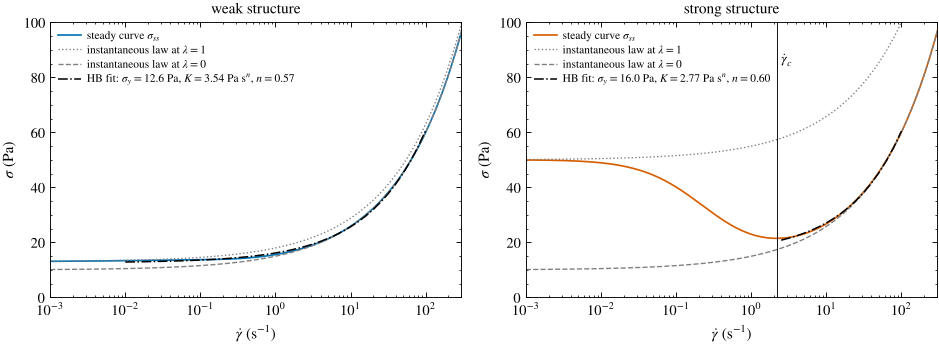

In [4]:
def fit_hb(gdot, sigma):
    r = least_squares(lambda q: hb_stress(gdot, *q) - sigma, [10.0, 5.0, 0.5], bounds=([0, 0, 0.05], [np.inf, np.inf, 2.0]))
    return r.x, r.fun

gfit = np.logspace(-2, 2, 41)
fig, axes = plt.subplots(1, 2, figsize=(8.8, 3.4))
for ax, (name, p, col) in zip(axes, [("weak structure", WEAK, C["blue"]), ("strong structure", STRONG, C["red"])]):
    gg = np.logspace(-3, 2.5, 400)
    ax.semilogx(gg, stress_ss(gg, p), color=col, label=r"steady curve $\sigma_{ss}$")
    ax.semilogx(gg, stress(1.0, gg, p), color=C["grey"], ls=":", lw=0.9, label=r"instantaneous law at $\lambda=1$")
    ax.semilogx(gg, stress(0.0, gg, p), color=C["grey"], ls="--", lw=0.9, label=r"instantaneous law at $\lambda=0$")
    if name.startswith("weak"):
        sel = gfit
    else:
        gc = brentq(lambda x: dstress_ss(x, STRONG), 0.5, 10)
        sel = gfit[gfit > gc]
        ax.axvline(gc, color="k", lw=0.6)
        ax.text(gc * 1.15, 85, r"$\dot\gamma_c$", fontsize=9)
    q, res = fit_hb(sel, stress_ss(sel, p))
    ax.semilogx(sel, hb_stress(sel, *q), "k-.", lw=1, label=rf"HB fit: $\sigma_y={q[0]:.1f}$ Pa, $K={q[1]:.2f}$ Pa s$^n$, $n={q[2]:.2f}$")
    ax.set(xlabel=r"$\dot\gamma$ (s$^{-1}$)", ylabel=r"$\sigma$ (Pa)", title=name, xlim=(1e-3, 300), ylim=(0, 100))
    ax.legend(fontsize=7.5, loc="upper left")
    print(f"{name}: HB fit sigma_y = {q[0]:.2f} Pa, K = {q[1]:.2f} Pa s^n, n = {q[2]:.3f};  "
          f"rms residual {np.sqrt(np.mean(res**2)):.2f} Pa, largest {np.abs(res).max():.2f} Pa  "
          f"(static yield stress {p['sigma_b'] + p['sigma_lambda']:.0f} Pa, instantaneous K = 5, n = 0.5)")
for a in axes: a.title.set_fontsize(10)
fig.tight_layout()
plt.show()

For the weak material the HB fit looks acceptable (residuals below 1 Pa), yet it returns $K=3.5$ Pa s$^n$ and $n=0.57$ instead of the instantaneous 5 and 0.5, and an intercept of 12.6 Pa that is neither $\sigma_b=10$ Pa nor the static 13 Pa: the fitted triplet describes the steady curve, not the law at fixed structure. For the strong material the fit to the stable branch gives an intercept of 16 Pa — a dynamic value, well below the static 50 Pa — and the whole region below $\dot\gamma_c$ is outside the fit's domain. The steady curve lies between the two instantaneous laws (dotted, $\lambda=1$; dashed, $\lambda=0$) and crosses from one to the other as the rate increases, which is exactly why it is not HB.

## 4. Transients with `solve_ivp`

### 4.1 Rest recovery

A sample pre-sheared at 100 s$^{-1}$ ($\lambda_{ss}=0.0025$) is left at rest. We integrate Eq. (S32) with $\dot\gamma=0$ and compare with the closed form $\lambda(t)=1-[1-\lambda(0)]e^{-at}$ of Note S13. In the model the mechanical observable linked to $\lambda$ is the static yield stress $\sigma_b+\sigma_\lambda\lambda$ (the stress needed to restart the rested sample, Eq. (S33) at $\dot\gamma\to0^+$).

rest recovery: solve_ivp and the closed form agree to 2.0e-11
  after  10 s of rest: lambda = 0.395, static yield stress sigma_b + sigma_lambda lambda = 25.8 Pa
  after  30 s of rest: lambda = 0.777, static yield stress sigma_b + sigma_lambda lambda = 41.1 Pa
  after 100 s of rest: lambda = 0.993, static yield stress sigma_b + sigma_lambda lambda = 49.7 Pa


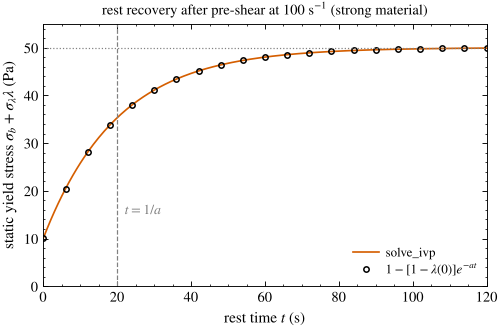

In [5]:
p = STRONG
lam_pre = lambda_ss(100.0, p)
t_rest = np.linspace(0, 120, 241)
sol = solve_ivp(lambda t, y: [lambda_rate(y[0], 0.0, p)], (0, 120), [lam_pre], t_eval=t_rest, rtol=1e-10, atol=1e-12)
lam_closed = 1 - (1 - lam_pre) * np.exp(-p["a"] * t_rest)
assert np.allclose(sol.y[0], lam_closed, atol=1e-8)
print(f"rest recovery: solve_ivp and the closed form agree to {np.max(np.abs(sol.y[0] - lam_closed)):.1e}")
for tw in [10, 30, 100]:
    lam_w = 1 - (1 - lam_pre) * np.exp(-p["a"] * tw)
    print(f"  after {tw:3d} s of rest: lambda = {lam_w:.3f}, static yield stress sigma_b + sigma_lambda lambda = {stress(lam_w, 0.0, p):.1f} Pa")

fig, ax = plt.subplots(figsize=(5.2, 3.1))
ax.plot(t_rest, stress(sol.y[0], 0.0, p), color=C["red"], label="solve_ivp")
ax.plot(t_rest[::12], stress(lam_closed[::12], 0.0, p), "o", ms=3.5, mfc="none", color=C["black"], label=r"$1-[1-\lambda(0)]e^{-at}$")
ax.axhline(p["sigma_b"] + p["sigma_lambda"], color=C["grey"], ls=":", lw=0.8)
ax.axvline(1 / p["a"], color=C["grey"], ls="--", lw=0.8)
ax.text(1 / p["a"] + 2, 15, r"$t=1/a$", fontsize=9, color=C["grey"])
ax.set(xlabel="rest time $t$ (s)", ylabel=r"static yield stress $\sigma_b+\sigma_\lambda\lambda$ (Pa)", xlim=(0, 120), ylim=(0, 55),
       title="rest recovery after pre-shear at 100 s$^{-1}$ (strong material)")
ax.title.set_fontsize(9.5)
ax.legend(fontsize=8.5, loc="lower right")
plt.show()

The static yield stress climbs from 10 Pa to 50 Pa with a time constant $1/a=20$ s. A rest-time series of breakaway stresses (listed in Table XIII for restart after shutdown) therefore measures $a$ directly — provided the observable is really linked to $\lambda$ in this way.

### 4.2 Rate steps

Next the sample is sheared steadily at 30 s$^{-1}$, stepped down to 3 s$^{-1}$ for 15 s, then stepped back up (both rates lie on the stable branch above $\dot\gamma_c$). At each step the viscous term $K\dot\gamma^n$ changes instantly while $\lambda$ relaxes with the time constant $t_\lambda=1/(a+b\dot\gamma^c)$ of the **new** rate: 1.54 s at 3 s$^{-1}$, 0.165 s at 30 s$^{-1}$. We recover these time constants from the simulated stress record by fitting the logarithm of the stress excess.

step to  3.0 1/s: fitted time constant 1.538 s;  t_lambda = 1/(a + b gdot^c) = 1.538 s
step to 30.0 1/s: fitted time constant 0.165 s;  t_lambda = 1/(a + b gdot^c) = 0.165 s


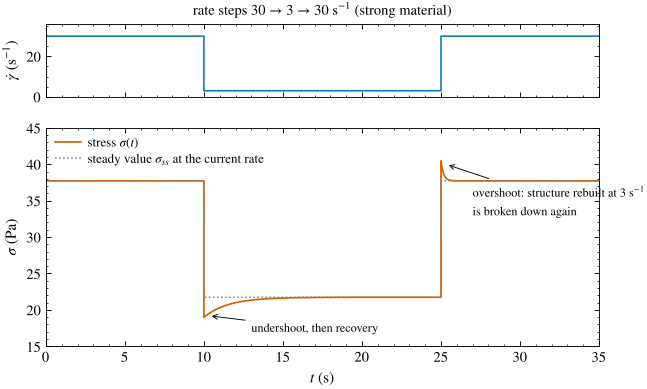

In [6]:
p = STRONG
protocol = [(30.0, 10.0), (3.0, 15.0), (30.0, 10.0)]          # (rate, duration)
t_all, lam_all, g_all = [], [], []
lam, t0 = lambda_ss(30.0, p), 0.0
for gdot, dur in protocol:
    tt = np.linspace(0, dur, 2001)
    sol = solve_ivp(lambda t, y: [lambda_rate(y[0], gdot, p)], (0, dur), [lam], t_eval=tt, rtol=1e-10, atol=1e-12)
    t_all.append(t0 + tt); lam_all.append(sol.y[0]); g_all.append(np.full_like(tt, gdot))
    lam, t0 = sol.y[0][-1], t0 + dur
t_all, lam_all, g_all = map(np.concatenate, (t_all, lam_all, g_all))
sig_all = stress(lam_all, g_all, p)

# time constants from the stress record: ln|sigma(t) - sigma_ss| is linear with slope -1/t_lambda
for gdot, t_start in [(3.0, 10.0), (30.0, 25.0)]:
    sel = (t_all > t_start + 0.01) & (t_all < t_start + 2.5 * t_lambda(gdot, p))
    slope = np.polyfit(t_all[sel], np.log(np.abs(sig_all[sel] - stress_ss(gdot, p))), 1)[0]
    print(f"step to {gdot:4.1f} 1/s: fitted time constant {-1 / slope:.3f} s;  t_lambda = 1/(a + b gdot^c) = {t_lambda(gdot, p):.3f} s")
    assert np.isclose(-1 / slope, t_lambda(gdot, p), rtol=1e-3)

fig, (axr, ax) = plt.subplots(2, 1, figsize=(6.2, 3.8), sharex=True, gridspec_kw={"height_ratios": [1, 3]})
axr.step(t_all, g_all, where="post", color=C["blue"], lw=1)
axr.set(ylabel=r"$\dot\gamma$ (s$^{-1}$)", ylim=(0, 36), title="rate steps 30 → 3 → 30 s$^{-1}$ (strong material)")
ax.plot(t_all, sig_all, color=C["red"], label=r"stress $\sigma(t)$")
ax.plot(t_all, stress_ss(g_all, p), color=C["grey"], ls=":", lw=1, label=r"steady value $\sigma_{ss}$ at the current rate")
ax.annotate("overshoot: structure rebuilt at 3 s$^{-1}$\nis broken down again", (25.3, 40.0), xytext=(27, 33), fontsize=8,
            arrowprops=dict(arrowstyle="->", lw=0.6))
ax.annotate("undershoot, then recovery", (10.3, 19.2), xytext=(13, 17), fontsize=8, arrowprops=dict(arrowstyle="->", lw=0.6))
ax.set(xlabel="$t$ (s)", ylabel=r"$\sigma$ (Pa)", xlim=(0, 35), ylim=(15, 45))
axr.title.set_fontsize(9.5)
ax.legend(fontsize=8.5, loc="upper left")
fig.tight_layout()
plt.show()

On the step down the stress first drops (less viscous stress) and then **rises** as structure rebuilds; on the step up it jumps and then **decays** as the rebuilt structure is broken again — a stress overshoot, the classic signature of thixotropy. The time constant of the relaxation is $a+b\dot\gamma^c$ at the new rate, as Note S13 states, so a rate-step test measures that combination; together with $a$ from Sec. 4.1 it yields $b$.

### 4.3 Flow-curve sweeps and hysteresis

A rheometer "flow curve" is a sequence of rate steps with a finite dwell time at each. We simulate descending sweeps (25 logarithmic steps from 100 to 0.01 s$^{-1}$, starting from the steady state at 100 s$^{-1}$) with dwell times of 2, 10 and 60 s, and an ascending sweep from a fully rested sample ($\lambda=1$) with a 10 s dwell, recording the stress at the end of each step. We use the closed form `lambda_const_rate` step by step (it is exact for piecewise-constant rates) and verify it once against `solve_ivp`.

stepped-sweep closed form agrees with solve_ivp (rtol 1e-8)


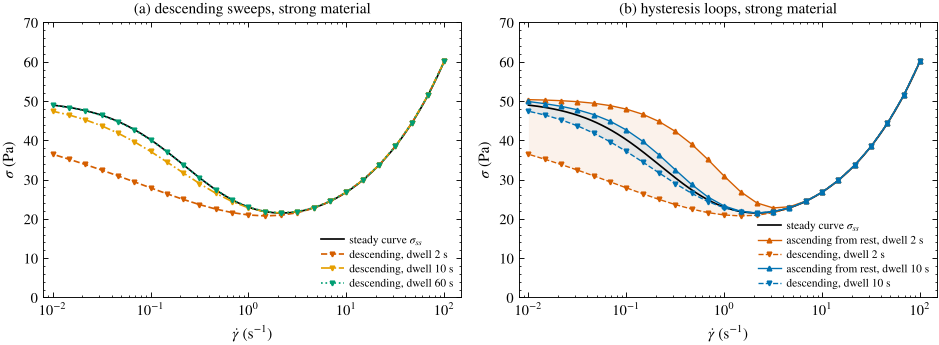

weak material: descending sweeps deviate from the steady curve by at most 1.05 Pa, the ascending sweep from rest by 0.20 Pa


In [7]:
def sweep(rates, dwell, lam0, p):
    """Stress at the end of each dwell of a stepped sweep; exact for piecewise-constant rate."""
    lam, out = lam0, []
    for gdot in rates:
        lam = lambda_const_rate(dwell, lam, gdot, p)
        out.append(stress(lam, gdot, p))
    return np.array(out)

def sweep_ivp(rates, dwell, lam0, p):
    lam, out = lam0, []
    for gdot in rates:
        lam = solve_ivp(lambda t, y: [lambda_rate(y[0], gdot, p)], (0, dwell), [lam], rtol=1e-10, atol=1e-12).y[0][-1]
        out.append(stress(lam, gdot, p))
    return np.array(out)

rates_down = np.logspace(2, -2, 25)
p = STRONG
assert np.allclose(sweep(rates_down, 10.0, lambda_ss(100.0, p), p), sweep_ivp(rates_down, 10.0, lambda_ss(100.0, p), p), rtol=1e-8)
print("stepped-sweep closed form agrees with solve_ivp (rtol 1e-8)")

p = STRONG
gg = np.logspace(-2, 2, 300)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8.8, 3.4))
ax1.semilogx(gg, stress_ss(gg, p), color=C["black"], label=r"steady curve $\sigma_{ss}$")
for dwell, col, ls in zip([2.0, 10.0, 60.0], [C["red"], C["orange"], C["green"]], ["--", "-.", ":"]):
    ax1.semilogx(rates_down, sweep(rates_down, dwell, lambda_ss(100.0, p), p), color=col, ls=ls, marker="v", ms=3,
                 label=f"descending, dwell {dwell:.0f} s")
ax1.set(xlabel=r"$\dot\gamma$ (s$^{-1}$)", ylabel=r"$\sigma$ (Pa)", title="(a) descending sweeps, strong material", xlim=(8e-3, 150), ylim=(0, 70))
ax1.legend(fontsize=7.5, loc="lower right")
ax2.semilogx(gg, stress_ss(gg, p), color=C["black"], label=r"steady curve $\sigma_{ss}$")
for dwell, col in zip([2.0, 10.0], [C["red"], C["blue"]]):
    up = sweep(rates_down[::-1], dwell, 1.0, p)
    down = sweep(rates_down, dwell, lambda_ss(100.0, p), p)
    ax2.semilogx(rates_down[::-1], up, color=col, marker="^", ms=3, lw=0.9, label=f"ascending from rest, dwell {dwell:.0f} s")
    ax2.semilogx(rates_down, down, color=col, ls="--", marker="v", ms=3, lw=0.9, label=f"descending, dwell {dwell:.0f} s")
    ax2.fill_between(rates_down[::-1], down[::-1], up, color=col, alpha=0.08, lw=0)
ax2.set(xlabel=r"$\dot\gamma$ (s$^{-1}$)", ylabel=r"$\sigma$ (Pa)", title="(b) hysteresis loops, strong material", xlim=(8e-3, 150), ylim=(0, 70))
ax2.legend(fontsize=7.5, loc="lower right")
for a in (ax1, ax2): a.title.set_fontsize(10)
fig.tight_layout()
plt.show()

# the weak material: all sweeps stay within a fraction of a pascal of the steady curve
p = WEAK
dev = max(np.abs(sweep(rates_down, d, lambda_ss(100.0, p), p) - stress_ss(rates_down, p)).max() for d in [2.0, 10.0, 60.0])
dev_up = np.abs(sweep(rates_down[::-1], 10.0, 1.0, p) - stress_ss(rates_down[::-1], p)).max()
print(f"weak material: descending sweeps deviate from the steady curve by at most {dev:.2f} Pa, the ascending sweep from rest by {dev_up:.2f} Pa")

With a 60 s dwell (three recovery times) the descending sweep follows the steady curve closely; with 2 s it lags behind at low rates, where $t_\lambda\to1/a=20$ s, and reads **lower** stresses than steady state because the structure has not had time to rebuild. The ascending sweep from rest starts at the static yield stress (50 Pa) and runs **above** the steady curve, because the structure has not had time to break down: the loop between the two sweeps at the same dwell is the thixotropic hysteresis loop (shaded), wide for a 2 s dwell and narrow for 10 s. Its area depends on the dwell time as much as on the material, which is why the review (Sec. VIII B) says that the area of a hysteresis loop does not determine the kinetics uniquely. For the strong material, remember that the homogeneous model keeps following the unstable branch below $\dot\gamma_c\approx2$ s$^{-1}$; a real sample would band there and the rheometer would record a nearly flat stress near $\sigma_{ss}(\dot\gamma_c)$ (Sec. V B). For the weak material every sweep stays within about 1 Pa of the steady curve: thixotropy with a small structural amplitude is invisible in a flow curve, whatever the protocol.

### 4.4 Creep and the viscosity bifurcation

Under an imposed stress $\sigma_0$ the shear rate follows from Eq. (S33), $\dot\gamma=[(\sigma_0-\sigma_b-\sigma_\lambda\lambda)/K]^{1/n}$ if the bracket is positive and zero otherwise, and $\lambda$ obeys Eq. (S32). We start from a partly rebuilt sample ($\lambda_0=0.5$, static yield stress $\sigma_b+\sigma_\lambda\lambda_0=30$ Pa) and apply stresses from 30 to 40 Pa.

sigma_0 = 30.0 Pa: initial rate 0.00 1/s, after 60 s 0 1/s, lambda = 0.975  (stopped: lambda -> 1)
sigma_0 = 32.0 Pa: initial rate 0.16 1/s, after 60 s 0 1/s, lambda = 0.974  (stopped: lambda -> 1)
sigma_0 = 32.4 Pa: initial rate 0.23 1/s, after 60 s 0 1/s, lambda = 0.971  (stopped: lambda -> 1)
sigma_0 = 32.6 Pa: initial rate 0.27 1/s, after 60 s 19.5 1/s, lambda = 0.013  (flows)
sigma_0 = 33.0 Pa: initial rate 0.36 1/s, after 60 s 20.3 1/s, lambda = 0.012  (flows)
sigma_0 = 35.0 Pa: initial rate 1.00 1/s, after 60 s 24.2 1/s, lambda = 0.010  (flows)
sigma_0 = 40.0 Pa: initial rate 4.00 1/s, after 60 s 35.3 1/s, lambda = 0.007  (flows)


critical stress right after pre-shear: 21.5 Pa (= minimum of the steady curve, 21.5 Pa); after 200 s of rest: 50.0 Pa (static value 50 Pa)


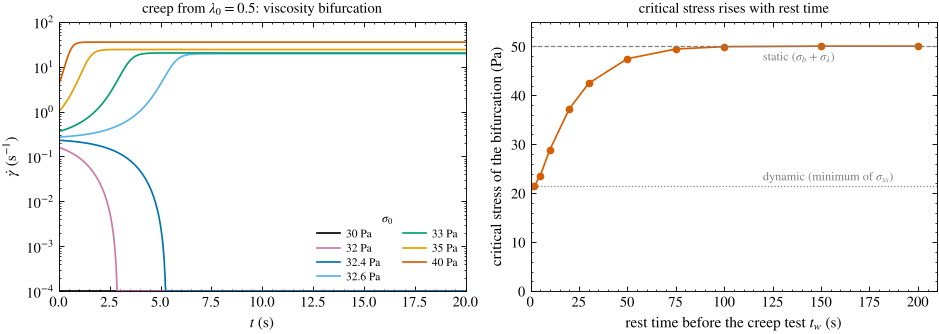

In [8]:
p = STRONG

def creep(sigma0, lam0, p, T=300.0, npts=600):
    def gdot_of(lam):
        return np.clip((sigma0 - p["sigma_b"] - p["sigma_lambda"] * lam) / p["K"], 0.0, None) ** (1 / p["n"])
    sol = solve_ivp(lambda t, y: [lambda_rate(y[0], gdot_of(y[0]), p)], (0, T), [lam0],
                    t_eval=np.linspace(0, T, npts), method="LSODA", rtol=1e-9, atol=1e-12)
    return sol.t, sol.y[0], gdot_of(sol.y[0])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8.8, 3.3))
for sigma0, col in zip([30, 32, 32.4, 32.6, 33, 35, 40], [C["black"], C["purple"], C["blue"], C["cyan"], C["green"], C["orange"], C["red"]]):
    t, lam, gd = creep(sigma0, 0.5, p, T=60.0, npts=3001)
    ax1.semilogy(t, np.clip(gd, 1e-4, None), color=col, label=f"{sigma0} Pa")
    print(f"sigma_0 = {sigma0:4.1f} Pa: initial rate {gd[0]:.2f} 1/s, after 60 s {gd[-1]:.3g} 1/s, lambda = {lam[-1]:.3f}"
          + ("  (stopped: lambda -> 1)" if gd[-1] < 1e-6 else "  (flows)"))
ax1.set(xlabel="$t$ (s)", ylabel=r"$\dot\gamma$ (s$^{-1}$)", xlim=(0, 20), ylim=(1e-4, 100),
        title=r"creep from $\lambda_0=0.5$: viscosity bifurcation")
ax1.legend(fontsize=7.5, ncol=2, title=r"$\sigma_0$", title_fontsize=8)

# critical stress of the bifurcation as a function of the rest time before the creep test
def critical_stress(lam0, p):
    flows = lambda s0: creep(s0, lam0, p, T=600.0, npts=50)[2][-1] - 1e-3
    return brentq(flows, p["sigma_b"] + 1e-6, p["sigma_b"] + p["sigma_lambda"] + 1.0, xtol=1e-3)

lam_pre = lambda_ss(100.0, p)
t_w = np.array([0, 2, 5, 10, 20, 30, 50, 75, 100, 150, 200])
s_crit = np.array([critical_stress(1 - (1 - lam_pre) * np.exp(-p["a"] * tw), p) for tw in t_w])
gc = brentq(lambda x: dstress_ss(x, p), 0.5, 10)
print(f"critical stress right after pre-shear: {s_crit[0]:.1f} Pa (= minimum of the steady curve, {stress_ss(gc, p):.1f} Pa);"
      f" after 200 s of rest: {s_crit[-1]:.1f} Pa (static value {p['sigma_b'] + p['sigma_lambda']:.0f} Pa)")
assert np.isclose(s_crit[0], stress_ss(gc, p), atol=0.05) and np.isclose(s_crit[-1], p["sigma_b"] + p["sigma_lambda"], atol=0.1)
ax2.plot(t_w, s_crit, "o-", color=C["red"], ms=4)
ax2.axhline(stress_ss(gc, p), color=C["grey"], ls=":", lw=0.8); ax2.text(120, stress_ss(gc, p) + 1, "dynamic (minimum of $\\sigma_{ss}$)", fontsize=8, color=C["grey"])
ax2.axhline(p["sigma_b"] + p["sigma_lambda"], color=C["grey"], ls="--", lw=0.8); ax2.text(120, p["sigma_b"] + p["sigma_lambda"] - 3, r"static ($\sigma_b+\sigma_\lambda$)", fontsize=8, color=C["grey"])
ax2.set(xlabel="rest time before the creep test $t_w$ (s)", ylabel="critical stress of the bifurcation (Pa)", xlim=(0, 210), ylim=(0, 55),
        title="critical stress rises with rest time")
for a in (ax1, ax2): a.title.set_fontsize(9.5)
fig.tight_layout()
plt.show()

Between 32.4 and 32.6 Pa the long-time behavior switches from arrest ($\dot\gamma\to0$, $\lambda\to1$) to steady flow at a finite rate of tens of s$^{-1}$, and the initial rates on the two sides of the threshold are almost the same (about 0.25 s$^{-1}$) — the **viscosity bifurcation** of Coussot et al. (2002): there is no steady flow at small rates, so the rate jumps straight to the stable branch above $\dot\gamma_c$. The critical stress itself depends on the state of the sample: 21.5 Pa right after pre-shear (the dynamic value, the minimum of the steady curve) and 50 Pa after a long rest (the static value). This is the qualitative pattern reported for bentonite suspensions, whose critical stress rose from 9 to 26 Pa with rest time (Møller, Mewis and Bonn, 2006; Sec. IX B of the review): no fixed HB triplet describes such a material below $\dot\gamma_c$.

## 5. Identifiability: what a descending flow curve cannot tell

Note S13 says that a single descending flow curve cannot identify the time scale uniquely. We test this with synthetic data: a descending sweep of the strong material with a 10 s dwell and Gaussian noise of 0.5 Pa (fixed seed). We then evaluate the misfit $\chi^2=\sum_i(\sigma_i^{\rm model}-\sigma_i^{\rm data})^2/(0.5\,\mathrm{Pa})^2$ on a grid of $(a,b)$, with $c$ and $n$ fixed at their true values and the three **linear** parameters $(\sigma_b,\sigma_\lambda,K)$ re-optimized by linear least squares at every grid point (so the misfit is profiled over them). For comparison we compute the misfit of a rest-time series (static yield stress after 0–120 s of rest, same noise) as a function of $a$ alone.

minimum misfit 9.6 for 25 points at a = 0.072, b = 0.282 (true: 0.05, 0.2)
joint 95 % region of (a, b) (2 parameters, chi2 < min + 5.99): a from 0.040 to 0.247 s^-1  (a factor 6),
              b/a from 3.41 to 4.50  (true 4.0)
descending sweep, profile 95 % interval for a: 0.044-0.151 s^-1 (a factor 3.4); profile at a = 1 s^-1 is only 6.8 above the minimum
  -> the ratio b/a is well identified, the time scale only weakly
rest-time series alone: 95 % interval for a = 0.048-0.052 s^-1


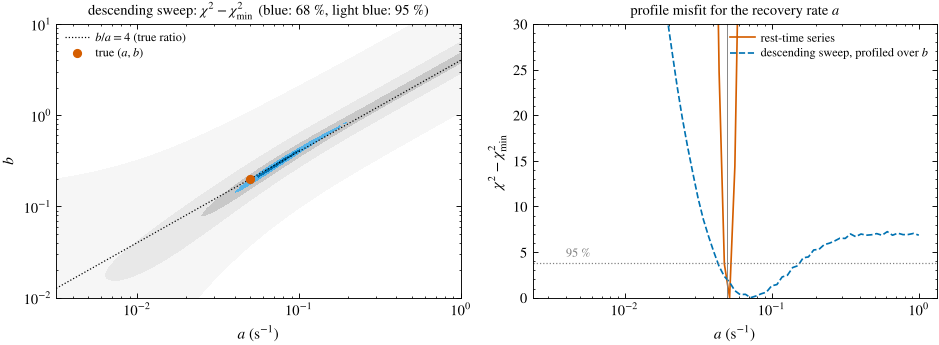

In [9]:
p_true = STRONG
noise = 0.5
sig_data = sweep(rates_down, 10.0, lambda_ss(100.0, p_true), p_true) + noise * rng.standard_normal(rates_down.size)

def sweep_lambda(rates, dwell, lam0, p):
    """Structure at the end of each dwell (depends on a, b, c only)."""
    lam, out = lam0, []
    for gdot in rates:
        lam = lambda_const_rate(dwell, lam, gdot, p)
        out.append(lam)
    return np.array(out)

def profiled_chi2(a, b):
    """Misfit of the descending sweep with (sigma_b, sigma_lambda, K) re-fitted by linear least squares."""
    p = dict(p_true, a=a, b=b)
    lam = sweep_lambda(rates_down, 10.0, lambda_ss(100.0, p), p)
    A = np.column_stack([np.ones_like(lam), lam, rates_down ** p["n"]])
    coef, *_ = np.linalg.lstsq(A, sig_data, rcond=None)
    return np.sum((A @ coef - sig_data) ** 2) / noise**2

a_grid = np.logspace(-2.5, 0.0, 71)
b_grid = np.logspace(-2.0, 1.0, 121)
chi2 = np.array([[profiled_chi2(a, b) for a in a_grid] for b in b_grid])
chi2_min = chi2.min()
i_b, i_a = np.unravel_index(chi2.argmin(), chi2.shape)
print(f"minimum misfit {chi2_min:.1f} for {rates_down.size} points at a = {a_grid[i_a]:.3f}, b = {b_grid[i_b]:.3f} (true: 0.05, 0.2)")
# extent of the 95 % region (chi2 < chi2_min + 5.99) along the ridge b = 4a and across it
inside = chi2 < chi2_min + 5.99
print(f"joint 95 % region of (a, b) (2 parameters, chi2 < min + 5.99): a from {a_grid[inside.any(axis=0)].min():.3f} to {a_grid[inside.any(axis=0)].max():.3f} s^-1  (a factor {a_grid[inside.any(axis=0)].max() / a_grid[inside.any(axis=0)].min():.0f}),")
ratio = (b_grid[:, None] / a_grid[None, :])[inside]
print(f"              b/a from {ratio.min():.2f} to {ratio.max():.2f}  (true 4.0)")
# profile over b (and the linear amplitudes) for a alone, analysed like the rest-time series (1 parameter, 3.84)
prof_a = chi2.min(axis=0) - chi2_min
in_prof = prof_a < 3.84
assert np.all(np.diff(np.flatnonzero(in_prof)) == 1)          # one contiguous interval
print(f"descending sweep, profile 95 % interval for a: {a_grid[in_prof].min():.3f}-{a_grid[in_prof].max():.3f} s^-1 "
      f"(a factor {a_grid[in_prof].max() / a_grid[in_prof].min():.1f}); profile at a = {a_grid[-1]:.0f} s^-1 is only "
      f"{prof_a[-1]:.1f} above the minimum")
print("  -> the ratio b/a is well identified, the time scale only weakly")

# rest-time series: static yield stress after rest t_w, noise 0.5 Pa
t_w = np.linspace(0, 120, 13)
lam_pre = lambda_ss(100.0, p_true)
static_data = stress(1 - (1 - lam_pre) * np.exp(-p_true["a"] * t_w), 0.0, p_true) + noise * rng.standard_normal(t_w.size)
def chi2_rest(a):
    lam = 1 - (1 - lam_pre) * np.exp(-a * t_w)
    A = np.column_stack([np.ones_like(lam), lam])
    coef, *_ = np.linalg.lstsq(A, static_data, rcond=None)
    return np.sum((A @ coef - static_data) ** 2) / noise**2
chi2_r = np.array([chi2_rest(a) for a in a_grid])
inside_r = chi2_r < chi2_r.min() + 3.84
print(f"rest-time series alone: 95 % interval for a = {a_grid[inside_r].min():.3f}-{a_grid[inside_r].max():.3f} s^-1")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8.8, 3.4))
cs = ax1.contourf(a_grid, b_grid, chi2 - chi2_min, levels=[0, 2.30, 5.99, 20, 100, 1000], colors=["#0072B2", "#56B4E9", "#c8c8c8", "#e8e8e8", "#f6f6f6"])
ax1.plot(a_grid, 4 * a_grid, "k:", lw=0.8, label="$b/a=4$ (true ratio)")
ax1.plot(0.05, 0.2, "o", color=C["red"], ms=5, label="true $(a,b)$")
ax1.set(xscale="log", yscale="log", xlabel="$a$ (s$^{-1}$)", ylabel="$b$", title=r"descending sweep: $\chi^2-\chi^2_{\min}$ (blue: 68 %, light blue: 95 %)")
ax1.legend(fontsize=8, loc="upper left")
ax2.semilogx(a_grid, chi2_r - chi2_r.min(), color=C["red"], label="rest-time series")
ax2.semilogx(a_grid, chi2.min(axis=0) - chi2_min, color=C["blue"], ls="--", label="descending sweep, profiled over $b$")
ax2.axhline(3.84, color=C["grey"], ls=":", lw=0.8); ax2.text(0.004, 4.5, "95 %", fontsize=8, color=C["grey"])
ax2.axvline(0.05, color=C["grey"], lw=0.6)
ax2.set(xlabel="$a$ (s$^{-1}$)", ylabel=r"$\chi^2-\chi^2_{\min}$", ylim=(0, 30), title="profile misfit for the recovery rate $a$")
ax2.legend(fontsize=8)
for a in (ax1, ax2): a.title.set_fontsize(9.5)
fig.tight_layout()
plt.show()

The joint 95 % region of the descending sweep is a long diagonal band in which $b/a$ is pinned between about 3.4 and 4.5. For $a$ alone, the profile 95 % interval ($\Delta\chi^2<3.84$, minimized over $b$ and the amplitudes) is 0.044–0.15 s$^{-1}$, a factor of about 3.4, and the profile levels off at $\Delta\chi^2\approx6.5$–7 for $a\gtrsim0.3$ s$^{-1}$, close to the one-parameter 99 % level (6.63), so at about 99 % confidence the sweep sets no upper bound on $a$. The sweep sees $\lambda_{ss}=1/(1+(b/a)\dot\gamma^c)$ plus a weak dwell-time effect that the re-fitted amplitudes absorb. The rest-time series, analysed the same way and with the same noise, gives 0.048–0.052 s$^{-1}$. With $a$ known, $b$ follows from the ratio (or from the rate-step time constant $a+b\dot\gamma^c$ of Sec. 4.2), and the steady amplitude gives $\sigma_\lambda$: this is the logic of independent excitation of Note S13, and the reason why Table XIII lists a rest-time series of breakaway stress for restart after shutdown.

## 6. A measured simple yield-stress fluid: the foam of Note S2

The counter-example is the SLES foam of Ovarlez, Krishan and Cohen-Addad (2010), re-analyzed in Supplementary Note S2 and in notebook 09. Its 152 local MRI flow-curve points lie on one continuous, monotone HB curve from 0.027 to 27 s$^{-1}$; the profile likelihood of a critical shear rate is flat up to the lowest observed rates and gives the 95 % bound $\dot\gamma_c<0.047$ s$^{-1}$, consistent with the source's own bound of about 0.04 s$^{-1}$ from the velocity profiles, while the 1.5 s$^{-1}$ predicted by a film-instability model is excluded. We reproduce the flow-curve panel of Fig. S1(a) from the stored fit and check it against `data/figure_data/figS1_foam.csv` and `data/foam_reanalysis_results.json`.

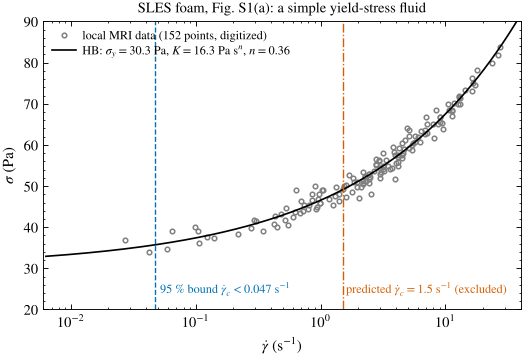

Fig. S1(a): HB curve and the 152 points agree with data/figure_data/figS1_foam.csv (rtol 1e-8); stored bound gamma_c < 0.047 1/s, lowest observed rate 0.027 1/s; the monotone steady curve is HB with sigma_y = 30.3 Pa, n = 0.36


In [10]:
DATA = ROOT / "data"
foam = pd.read_csv(DATA / "foam_sles_fig3b_digitized.csv")
stored = json.loads((DATA / "foam_reanalysis_results.json").read_text())
fd = pd.read_csv(DATA / "figure_data" / "figS1_foam.csv", comment="#")
sy_f, K_f, n_f = stored["HB"]["parameters"]
gc_bound = stored["HB_gc"]["upper_bound_95_s_inv"]

fig, ax = plt.subplots(figsize=(5.6, 3.4))
ax.semilogx(foam["shear_rate_s_inv"], foam["stress_Pa"], "o", ms=3, mfc="none", color=C["grey"], label="local MRI data (152 points, digitized)")
xx = np.logspace(-2.2, 1.6, 400)
ax.semilogx(xx, hb_stress(xx, sy_f, K_f, n_f), color=C["black"], label=rf"HB: $\sigma_y={sy_f:.1f}$ Pa, $K={K_f:.1f}$ Pa s$^n$, $n={n_f:.2f}$")
ax.axvline(gc_bound, color=C["blue"], ls="--", lw=0.9); ax.text(gc_bound * 1.1, 24, rf"95 % bound $\dot\gamma_c<{gc_bound:.3f}$ s$^{{-1}}$", fontsize=8, color=C["blue"])
ax.axvline(1.5, color=C["red"], ls="-.", lw=0.9); ax.text(1.6, 24, r"predicted $\dot\gamma_c=1.5$ s$^{-1}$ (excluded)", fontsize=8, color=C["red"])
ax.set(xlim=(6e-3, 40), ylim=(20, 90), xlabel=r"$\dot\gamma$ (s$^{-1}$)", ylabel=r"$\sigma$ (Pa)", title="SLES foam, Fig. S1(a): a simple yield-stress fluid")
ax.title.set_fontsize(9.5)
ax.legend(fontsize=8, loc="upper left")
plt.show()

# checks against the figure data and the stored results
s = fd[(fd.panel == "(a)") & (fd.series == "HB")].sort_values("index")
assert np.allclose(s.x.to_numpy(), xx, rtol=1e-8) and np.allclose(s.y.to_numpy(), hb_stress(xx, sy_f, K_f, n_f), rtol=1e-8)
assert len(fd[(fd.panel == "(a)") & (fd.kind == "markers")]) == len(foam) == 152
assert np.isclose(fd.loc[fd.series == "predicted critical shear rate", "x"].item(), 1.5)
assert np.isclose(fd.loc[fd.series == "bound on critical shear rate reported by the source", "x"].item(), 0.04)
assert round(gc_bound, 3) == 0.047 and round(sy_f, 1) == 30.3 and round(n_f, 2) == 0.36
print(f"Fig. S1(a): HB curve and the 152 points agree with data/figure_data/figS1_foam.csv (rtol 1e-8); "
      f"stored bound gamma_c < {gc_bound:.3f} 1/s, lowest observed rate {foam['shear_rate_s_inv'].min():.3f} 1/s; "
      f"the monotone steady curve is HB with sigma_y = {sy_f:.1f} Pa, n = {n_f:.2f}")

This is what "simple" looks like in data: one monotone curve, steady flow at every rate down to the resolution of the measurement, and no history dependence within experimental resolution (Ovarlez et al., 2013). For such a material the HB triplet is a property of the material; for the strong thixotropic material of Secs. 3–5 it is a property of the protocol. The review's two bentonite examples (Sec. IX B) show the thixotropic side with measured numbers: adding bentonite to an emulsion that follows HB with $\sigma_y=50.5$ Pa, $n=0.55$ and $\dot\gamma_c\to0$ created a critical shear rate of 0.6 s$^{-1}$ (Fall, Paredes and Bonn, 2010), and in bentonite suspensions the critical stress of the bifurcation rose from 9 to 26 Pa with rest time (Møller, Mewis and Bonn, 2006). For an industrial example of a structure-dependent HB framework, Sec. VIII B cites Li et al. (2026), who let $\sigma_y$, $K$ and $n$ depend on a structural parameter encoding the inherited shear history of a semisolid aluminum slurry; this raised the coefficient of determination of apparent viscosities computed from process signals from 0.285 to 0.901, with a 29 % error remaining in extrapolation beyond the calibration range.

## 7. Try it yourself

**Exercise 1 — a different breakdown exponent.** Repeat Sec. 3.1 with $c=2$ (and $b=0.2$ s, so that $b\dot\gamma^2$ is a rate). Is the strong material's steady curve still non-monotone? Where is $\dot\gamma_c$ now, and what is the dynamic yield stress?

*Hint:* `p = dict(STRONG, c=2.0)`; look for sign changes of `dstress_ss`.

<details><summary>Solution</summary>

```python
p = dict(STRONG, c=2.0)
d = dstress_ss(g_grid, p)
idx = np.flatnonzero(np.sign(d[:-1]) != np.sign(d[1:]))
roots = [brentq(lambda x: dstress_ss(x, p), g_grid[i], g_grid[i + 1]) for i in idx]
print(roots, [stress_ss(r, p) for r in roots])
# Still non-monotone: a local maximum at 0.040 1/s (50.7 Pa) and a minimum at gamma_c = 2.21 1/s where
# sigma_ss = 19.4 Pa. The critical rate hardly moves, but the dynamic yield stress is lower than with c = 1
# (21.5 Pa) because above 1 1/s the structure breaks down faster (b gdot^2 > b gdot), and below 1 1/s it
# survives better, which is why the local maximum moves up from 2e-4 to 0.04 1/s.
```
</details>

**Exercise 2 — hysteresis-loop area.** For the strong material, compute the area between the ascending (from rest) and descending sweeps of Sec. 4.3, $\oint\sigma\,\mathrm d\ln\dot\gamma$, for dwell times of 2, 5, 10, 30 and 100 s. Then show that a material with $(a,b)$ twice as large and the same $b/a$ gives the same area at a dwell time half as long. What does this say about identifying $a$ from the loop area (de Souza Mendes and Thompson, 2012)?

*Hint:* use `np.trapezoid` on $\ln\dot\gamma$.

<details><summary>Solution</summary>

```python
def loop_area(p, dwell):
    up = sweep(rates_down[::-1], dwell, 1.0, p); down = sweep(rates_down, dwell, lambda_ss(100.0, p), p)[::-1]
    return np.trapezoid(up - down, np.log(rates_down[::-1]))
for dwell in [2, 5, 10, 30, 100]:
    print(dwell, round(loop_area(STRONG, dwell), 1), round(loop_area(dict(STRONG, a=0.1, b=0.4), dwell / 2), 1))
# The area falls from about 86 Pa at 2 s to 17 Pa at 10 s and to zero at 100 s, when both sweeps are at steady
# state: it is a function of dwell x a (and of b/a), and the two materials give identical areas when the
# dwell is scaled by 1/2.
# The area depends on a only through a x dwell. A loop at one dwell is a single number shared among a, b/a and
# sigma_lambda, so different kinetic constants give the same area; separating them needs several dwells plus
# rest-time and rate-step data (de Souza Mendes and Thompson, 2012).
```
</details>

**Exercise 3 — a rate below $\dot\gamma_c$ in the homogeneous model.** Impose $\dot\gamma=0.5$ s$^{-1}$ (below $\dot\gamma_c\approx2.2$ s$^{-1}$) on the strong material starting from $\lambda=0.1$ and integrate for 200 s. What steady stress does the homogeneous model reach, and how does it compare with $\sigma_{ss}(\dot\gamma_c)$? Explain why a rheometer would record a stress near $\sigma_{ss}(\dot\gamma_c)$ instead (Sec. V B).

*Hint:* the lever rule: a band at $\dot\gamma_c$ occupying a fraction $0.5/2.2$ of the gap and the rest at rest.

<details><summary>Solution</summary>

```python
p = STRONG
sol = solve_ivp(lambda t, y: [lambda_rate(y[0], 0.5, p)], (0, 200), [0.1], rtol=1e-10, atol=1e-12)
print(stress(sol.y[0][-1], 0.5, p), stress_ss(0.5, p), stress_ss(gc, p))
# The homogeneous model settles at sigma_ss(0.5) = 26.9 Pa, on the decreasing (unstable) branch, 5 Pa above
# the minimum. In a real sample the flow splits into a band sheared at about gamma_c (fraction 0.5/2.2 = 23 %
# of the gap) and an arrested region, so the measured stress stays near sigma_ss(gamma_c) = 21.5 Pa: a flat
# plateau below gamma_c that a three-parameter HB fit would misread as a low-rate branch with an intercept
# of about 21 Pa, far below the static 50 Pa.
```
</details>

## Key points

* A simple yield-stress fluid has one steady flow curve, independent of history, stable down to zero rate; a thixotropic one shows a viscosity bifurcation in creep, a critical shear rate $\dot\gamma_c$ below which it bands, and static and dynamic yield stresses that differ.
* In the structural-kinetics model (S32)–(S33), $\lambda_{ss}=a/(a+b\dot\gamma^c)$ and $t_\lambda=1/(a+b\dot\gamma^c)$; the steady curve $\sigma_b+\sigma_\lambda\lambda_{ss}+K\dot\gamma^n$ is not HB, and it is non-monotone when $\sigma_\lambda$ exceeds a threshold set by $a$, $b$, $c$, $K$ and $n$ (3.8 Pa for the illustrative constants; the explicit condition is derived here, not in Note S13).
* An HB fit to the steady curve returns parameters that differ from the instantaneous $K$ and $n$, and an intercept that is a dynamic yield stress; on the stable branch of the strong material the fitted intercept is 16 Pa against a static value of 50 Pa.
* Rate steps produce stress overshoots that relax with the time constant of the **new** rate; descending sweeps with short dwells read below the steady curve; the loop between ascending and descending sweeps depends on the dwell as much as on the material.
* In creep the critical stress of the bifurcation depends on the rest time (21.5 Pa to 50 Pa in the model; 9 to 26 Pa for bentonite in the literature): no fixed triplet describes the material below $\dot\gamma_c$.
* A descending flow curve identifies only $b/a$ (and the amplitude); the recovery rate $a$ needs a rest-time series and $b$ a rate-step test — independent excitation.
* The SLES foam of Note S2 is the simple case: a monotone HB curve to 0.027 s$^{-1}$ with $\dot\gamma_c<0.047$ s$^{-1}$.

## References

The review and its repository:
* Y. Wang (2026). A century of the Herschel–Bulkley model (1926–2026): Widespread use, community achievements, predictive capability, and engineering implications. Manuscript submitted to the *Journal of Rheology*; code and data: https://github.com/ktwyw/hb-centenary-review

* Coussot, P., Nguyen, Q. D., Huynh, H. T., and Bonn, D. (2002). Viscosity bifurcation in thixotropic, yielding fluids. *Journal of Rheology* **46**, 573–589. https://doi.org/10.1122/1.1459447
* de Souza Mendes, P. R., and Thompson, R. L. (2012). A critical overview of elasto-viscoplastic thixotropic modeling. *Journal of Non-Newtonian Fluid Mechanics* **187–188**, 8–15. https://doi.org/10.1016/j.jnnfm.2012.08.006
* Fall, A., Paredes, J., and Bonn, D. (2010). Yielding and shear banding in soft glassy materials. *Physical Review Letters* **105**, 225502. https://doi.org/10.1103/PhysRevLett.105.225502
* Li, Z., Zhang, Q., Jansson, P., Tan, H., Lattanzi, L., and Jarfors, A. E. W. (2026). Process–microstructure–rheology linkage in industrial semi-solid processing: A shear-history-dependent Herschel–Bulkley framework. *Materials & Design* **271**, 117257. https://doi.org/10.1016/j.matdes.2026.117257
* Møller, P. C. F., Mewis, J., and Bonn, D. (2006). Yield stress and thixotropy: on the difficulty of measuring yield stresses in practice. *Soft Matter* **2**, 274–283. https://doi.org/10.1039/b517840a
* Ovarlez, G., Krishan, K., and Cohen-Addad, S. (2010). Investigation of shear banding in three-dimensional foams. *EPL* **91**, 68005. https://doi.org/10.1209/0295-5075/91/68005
* Ovarlez, G., Cohen-Addad, S., Krishan, K., Goyon, J., and Coussot, P. (2013). On the existence of a simple yield stress fluid behavior. *Journal of Non-Newtonian Fluid Mechanics* **193**, 68–79. https://doi.org/10.1016/j.jnnfm.2012.06.009

### Further reading

* Bonn, D., Denn, M. M., Berthier, L., Divoux, T., and Manneville, S. (2017). Yield stress materials in soft condensed matter. *Reviews of Modern Physics* **89**, 035005. https://doi.org/10.1103/revmodphys.89.035005
* Dinkgreve, M., Fazilati, M., Denn, M. M., and Bonn, D. (2018). Carbopol: From a simple to a thixotropic yield stress fluid. *Journal of Rheology* **62**, 773–780. https://doi.org/10.1122/1.5016034
* Larson, R. G., and Wei, Y. (2019). A review of thixotropy and its rheological modeling. *Journal of Rheology* **63**, 477–501. https://doi.org/10.1122/1.5055031
* Mewis, J., and Wagner, N. J. (2009). Thixotropy. *Advances in Colloid and Interface Science* **147–148**, 214–227. https://doi.org/10.1016/j.cis.2008.09.005
* Roussel, N. (2006). A thixotropy model for fresh fluid concretes: Theory, validation and applications. *Cement and Concrete Research* **36**, 1797–1806. https://doi.org/10.1016/j.cemconres.2006.05.025